# Support Vector Machine (SVM)

Support Vector Machine (SVM) is a supervised machine learning algorithm used for both classification and regression tasks. It is commonly applied to problems involving classification, pattern recognition, and prediction.

SVM works by finding an optimal decision boundary, known as a hyperplane, that separates data points into different classes. It aims to maximize the margin between the decision boundary and the closest data points from each class, known as support vectors.

For classification, SVM identifies a hyperplane that best separates the classes. For regression, Support Vector Regression (SVR) estimates a function that predicts continuous values while allowing a specified margin of error.

SVM can also handle nonlinear relationships through the use of kernel functions, which allow it to model complex patterns in data.

## How SVM Works

1. **Hyperplane:** Finds a decision boundary that separates data points.
2. **Margin:** Maximizes the distance between the hyperplane and the closest observations.
3. **Support vectors:** Uses the observations closest to the decision boundary to determine its position.
4. **Kernel trick:** Uses kernel functions to handle nonlinear relationships without explicitly transforming data into higher dimensions.
5. **Optimization:** Finds model parameters that balance prediction accuracy and model complexity.

## Common Kernel Functions

- **Linear:** Used when data can be separated approximately by a straight boundary.
- **Polynomial:** Captures relationships involving polynomial patterns.
- **RBF (Radial Basis Function):** Handles complex nonlinear relationships.
- **Sigmoid:** Uses a sigmoid-shaped kernel function.

##  Advantages

- Effective in high-dimensional feature spaces.
- Can model both linear and nonlinear relationships.
- Uses support vectors to determine decision boundaries.
- Can perform well on relatively small and medium-sized datasets.
- Supports both classification and regression.

## Limitations

- Can be computationally expensive on large datasets.
- Sensitive to feature scaling.
- Choosing suitable kernels and hyperparameters can be challenging.
- Less interpretable than simpler models.
- Performance depends on the quality of the selected kernel and parameters.

In [2]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR, SVC

from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score,accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report,roc_auc_score,roc_curve)


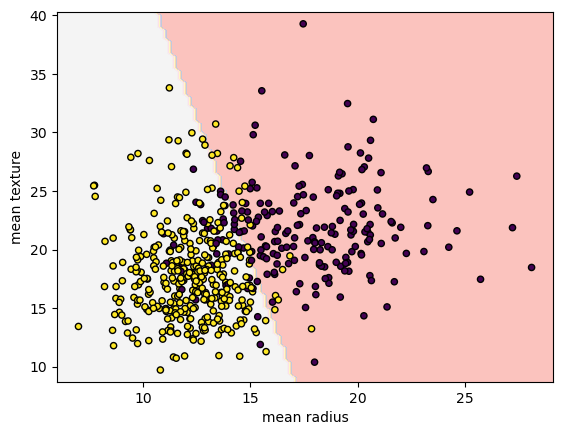

In [4]:
from sklearn.datasets import load_breast_cancer
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.svm import SVC

cancer = load_breast_cancer()
X = cancer.data[:, :2]
y = cancer.target

svm = SVC(kernel="linear", C=1)
svm.fit(X, y)

DecisionBoundaryDisplay.from_estimator(
        svm,
        X,
        response_method="predict",
        alpha=0.8,
        cmap="Pastel1",
        xlabel=cancer.feature_names[0],
        ylabel=cancer.feature_names[1],
    )

plt.scatter(X[:, 0], X[:, 1], 
            c=y, 
            s=20, edgecolors="k")
plt.show()

## Regression

In [6]:
# load dataset
housing = fetch_california_housing()

housing_df = pd.DataFrame(housing.data,columns=housing.feature_names)

housing_df['target'] = housing.target

housing_df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [7]:
# inspect dataset
# Dataset dimensions
print("Shape:", housing_df.shape)

# Dataset information
housing_df.info()

# Statistical summary
housing_df.describe()

Shape: (20640, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
 8   target      20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [8]:
# Missing values per column
housing_df.isnull().sum()

MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
target        0
dtype: int64

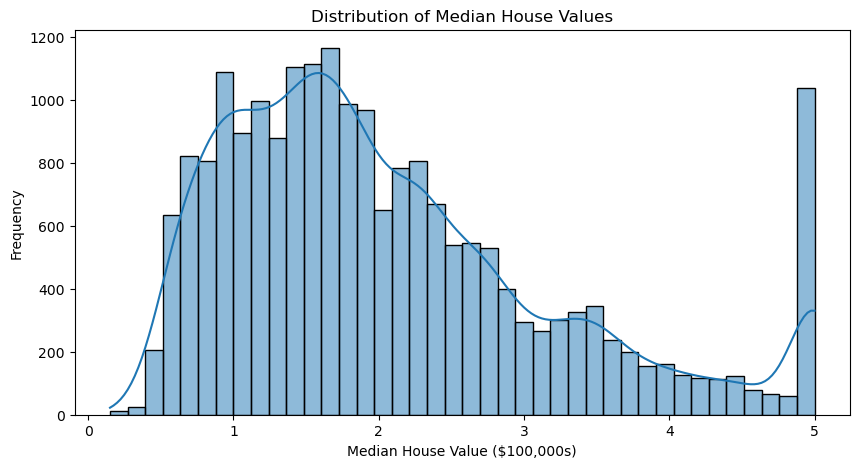

In [9]:
# Target variable
# Target distribution
plt.figure(figsize=(10, 5))

sns.histplot(housing_df['target'], bins=40, kde=True)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value ($100,000s)")
plt.ylabel("Frequency")

plt.show()

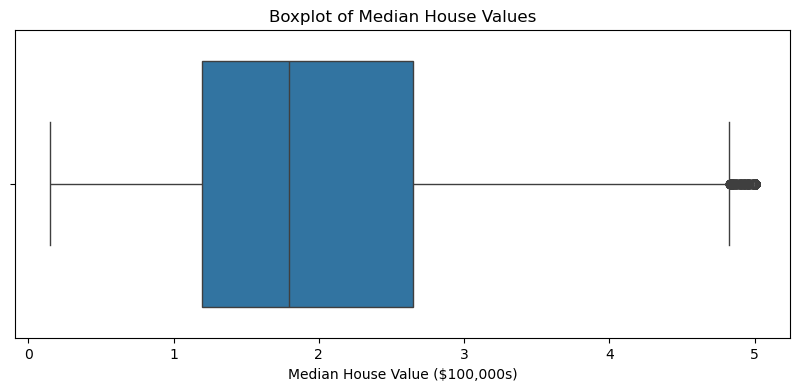

In [10]:
# Boxplot of target variable
plt.figure(figsize=(10, 4))

sns.boxplot(x=housing_df['target'])

plt.title("Boxplot of Median House Values")
plt.xlabel("Median House Value ($100,000s)")

plt.show()

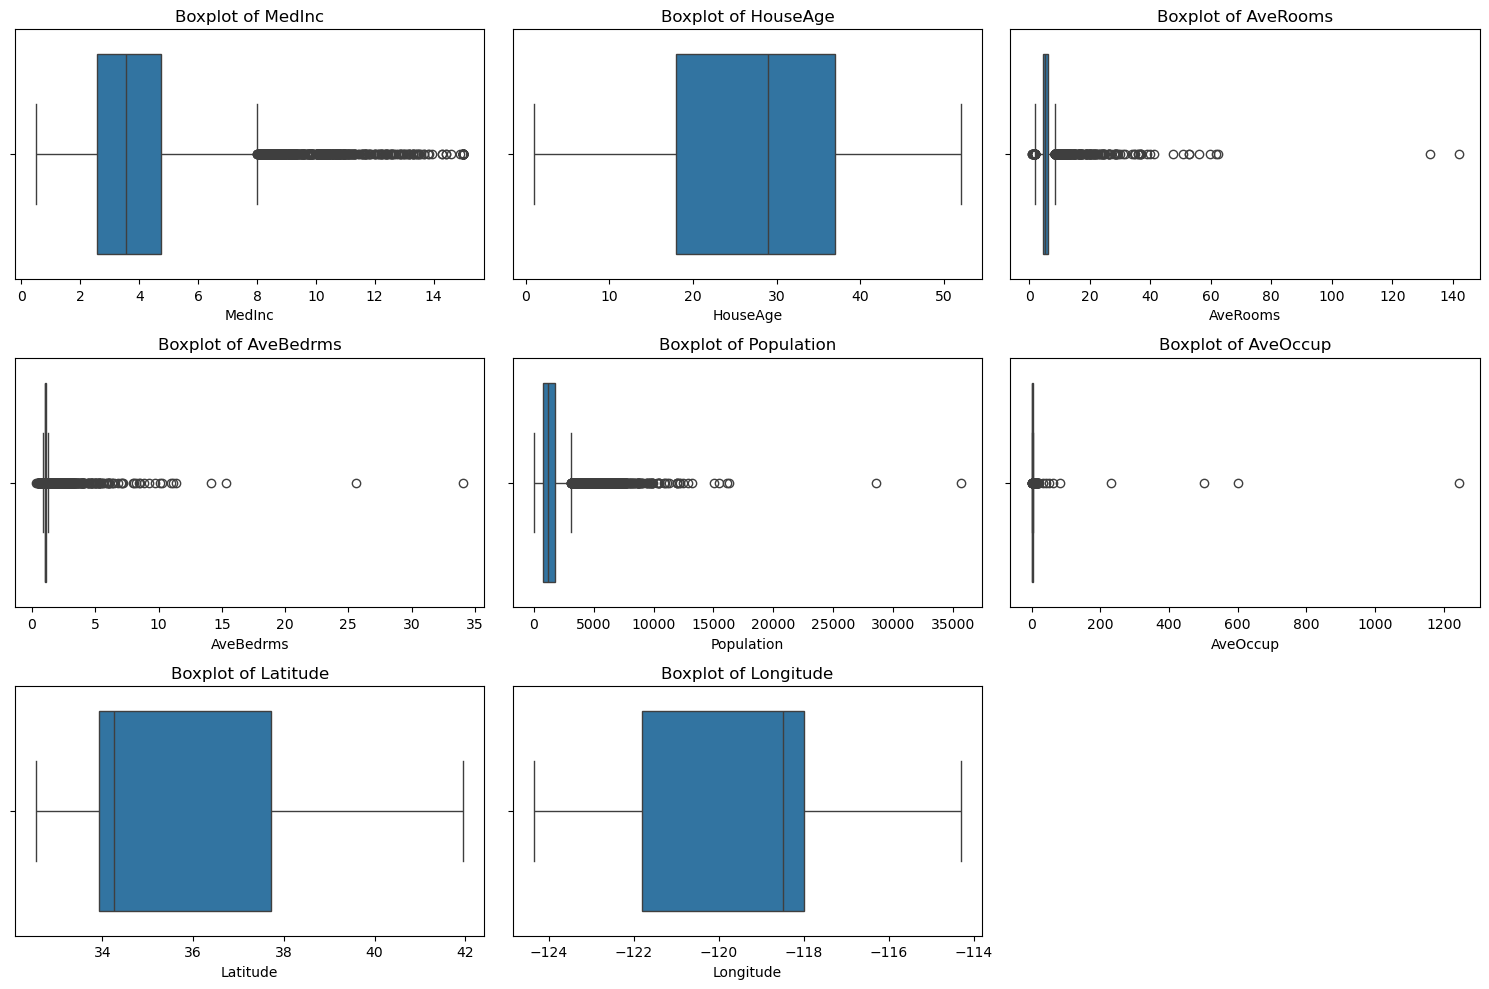

In [11]:
# Boxplots for numerical features
plt.figure(figsize=(15, 10))

for i, column in enumerate(housing_df.drop(columns='target').columns, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(x=housing_df[column])
    plt.title(f"Boxplot of {column}")

plt.tight_layout()
plt.show()

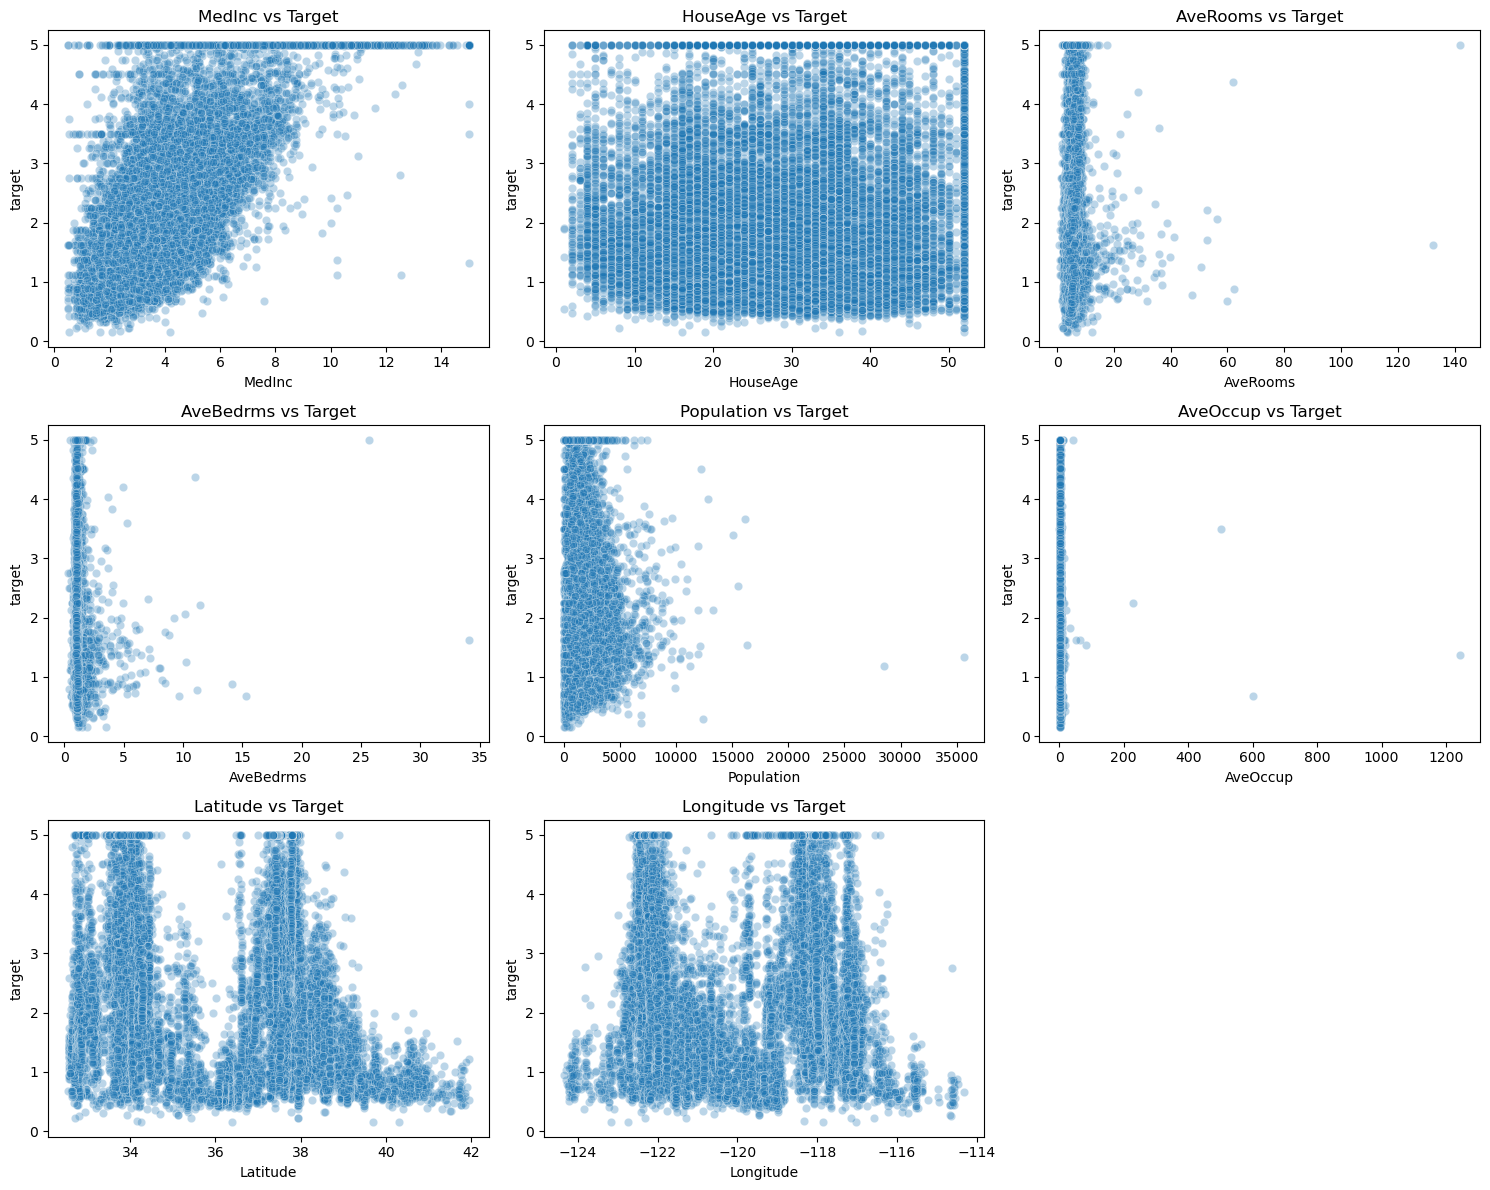

In [12]:
# Visualize feature-target relationships
plt.figure(figsize=(15, 12))

features = housing_df.drop(columns='target').columns

for i, column in enumerate(features, 1):
    plt.subplot(3, 3, i)

    sns.scatterplot(data=housing_df,x=column,y='target',alpha=0.3)

    plt.title(f"{column} vs Target")

plt.tight_layout()
plt.show()

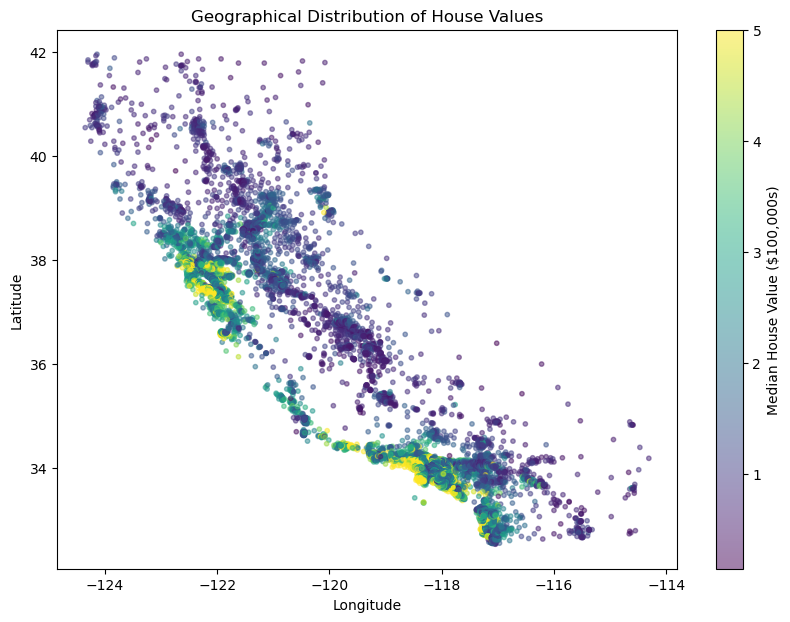

In [13]:
# geographical distribution
plt.figure(figsize=(10, 7))

scatter = plt.scatter(housing_df['Longitude'],housing_df['Latitude'],c=housing_df['target'],cmap='viridis',alpha=0.5,s=10)

plt.colorbar(scatter, label='Median House Value ($100,000s)')

plt.title("Geographical Distribution of House Values")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.show()

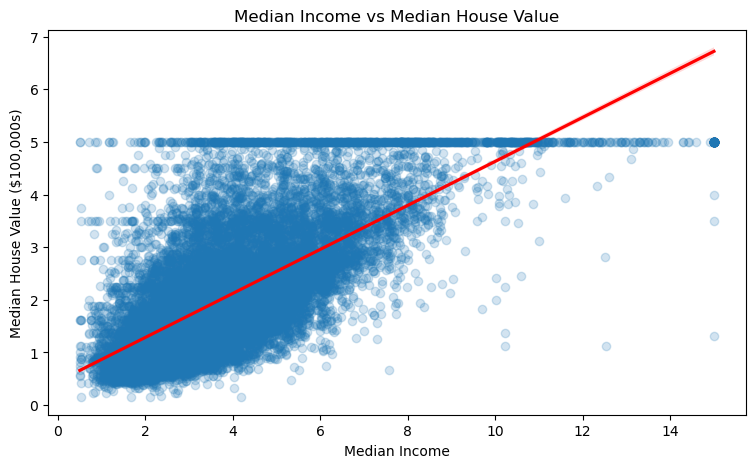

In [14]:
# Median income vs house value
plt.figure(figsize=(9, 5))

sns.regplot(data=housing_df,x='MedInc',y='target',scatter_kws={'alpha': 0.2},line_kws={'color': 'red'})

plt.title("Median Income vs Median House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value ($100,000s)")

plt.show()

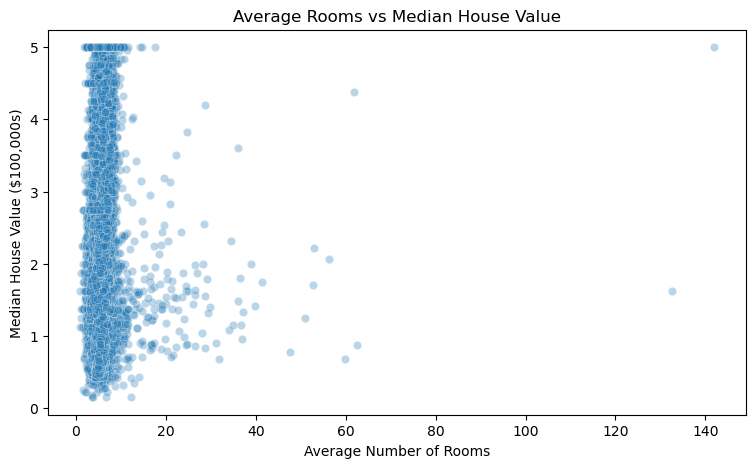

In [15]:
# Average rooms vs house value
plt.figure(figsize=(9, 5))

sns.scatterplot(data=housing_df,x='AveRooms',y='target',alpha=0.3)

plt.title("Average Rooms vs Median House Value")
plt.xlabel("Average Number of Rooms")
plt.ylabel("Median House Value ($100,000s)")

plt.show()

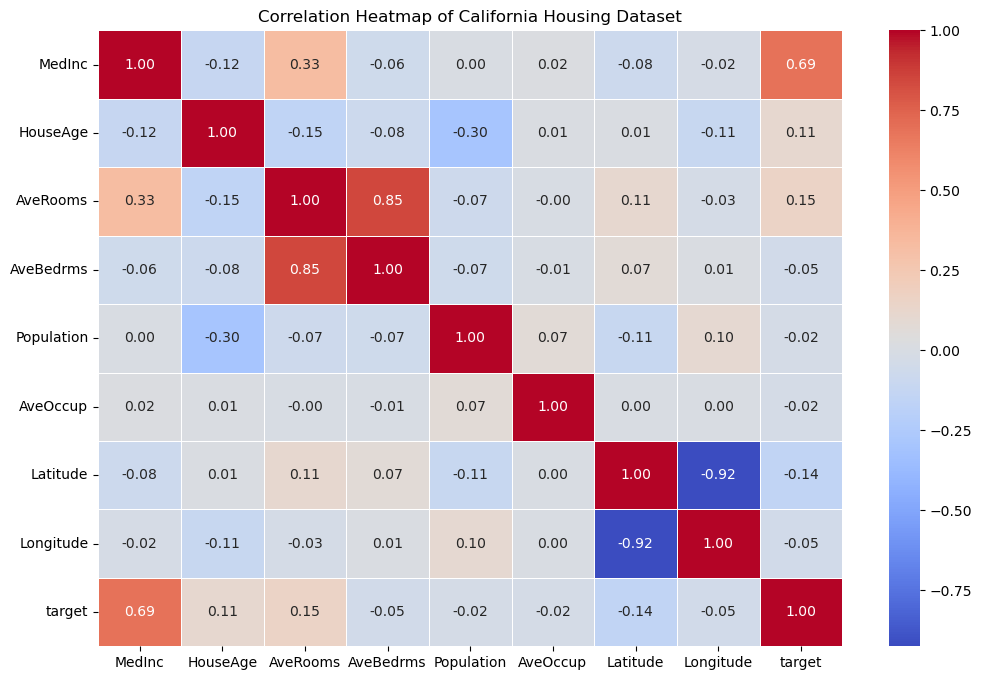

In [16]:
# Correlation matrix
correlation_matrix = housing_df.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(correlation_matrix,annot=True,cmap='coolwarm',fmt='.2f',linewidths=0.5)

plt.title("Correlation Heatmap of California Housing Dataset")

plt.show()

In [17]:
# Correlation of features with target
target_correlation = housing_df.corr()['target'].drop('target')

target_correlation.sort_values(ascending=False)

MedInc        0.688075
AveRooms      0.151948
HouseAge      0.105623
AveOccup     -0.023737
Population   -0.024650
Longitude    -0.045967
AveBedrms    -0.046701
Latitude     -0.144160
Name: target, dtype: float64

In [18]:
# Preprocessing
# features and targets
X = housing_df.drop(columns=['target']) # features
y = housing_df['target'] # target

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (20640, 8)
Target shape: (20640,)


In [19]:
# split dataset
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (16512, 8)
Testing features: (4128, 8)
Training target: (16512,)
Testing target: (4128,)


In [21]:
# feature scaling
from sklearn.preprocessing import StandardScaler
# Initialize the scaler
scaler = StandardScaler()

# Fit on training data and transform
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test)
print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Scaled training shape: (16512, 8)
Scaled testing shape: (4128, 8)


In [22]:
pd.DataFrame(X_train_scaled,columns=X.columns).head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,-0.326196,0.348490,-0.174916,-0.208365,0.768276,0.051376,-1.372811,1.272587
1,-0.035843,1.618118,-0.402835,-0.128530,-0.098901,-0.117362,-0.876696,0.709162
2,0.144701,-1.952710,0.088216,-0.257538,-0.449818,-0.032280,-0.460146,-0.447603
3,-1.017864,0.586545,-0.600015,-0.145156,-0.007434,0.077507,-1.382172,1.232698
4,-0.171488,1.142008,0.349007,0.086624,-0.485877,-0.068832,0.532084,-0.108551


In [23]:
# Modelling
svr_model = SVR(kernel='rbf',C=1.0,epsilon=0.1)
svr_model.fit(X_train_scaled, y_train) # train

,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,tol,0.001
,C,1.0
,epsilon,0.1
,shrinking,True
,cache_size,200
,verbose,False
,max_iter,-1


In [24]:
# predictions
# Training predictions
y_train_pred = svr_model.predict(X_train_scaled)

# Testing predictions
y_test_pred = svr_model.predict(X_test_scaled)

In [25]:
# evaluation
mae = mean_absolute_error(y_test, y_test_pred)
mse = mean_squared_error(y_test, y_test_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_test_pred)

print(f"MAE: {mae:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2 Score: {r2:.4f}")

MAE: 0.3986
MSE: 0.3570
RMSE: 0.5975
R2 Score: 0.7276


In [26]:
# training vs testing performance
train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("Training R2:", round(train_r2, 4))
print("Testing R2:", round(test_r2, 4))

Training R2: 0.7486
Testing R2: 0.7276


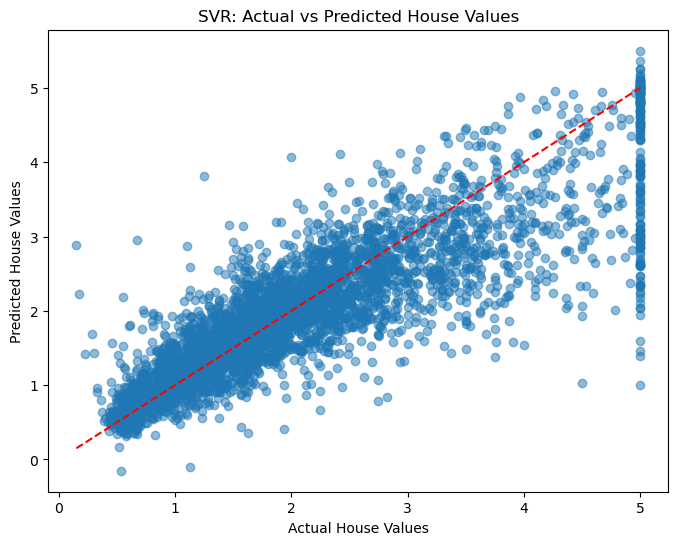

In [27]:
# Actual vs Predicted
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_test_pred, alpha=0.5)

plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()],color='red',linestyle='--')

plt.title("SVR: Actual vs Predicted House Values")
plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")

plt.show()

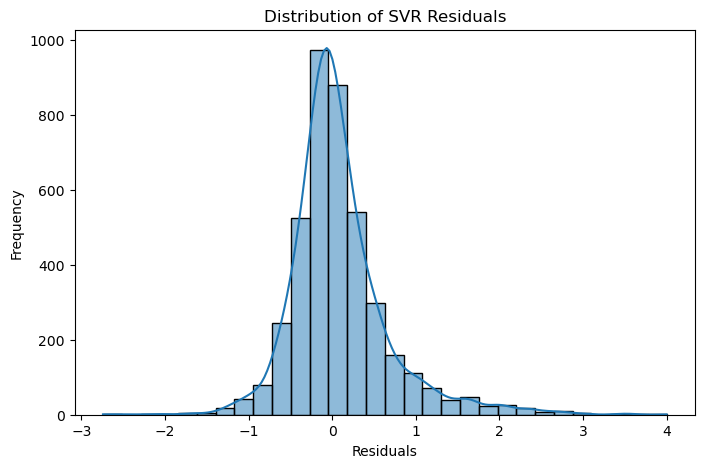

In [28]:
# Residual Analysis
residuals = y_test - y_test_pred
plt.figure(figsize=(8, 5))

sns.histplot(residuals, bins=30, kde=True)

plt.title("Distribution of SVR Residuals")
plt.xlabel("Residuals")
plt.ylabel("Frequency")

plt.show()

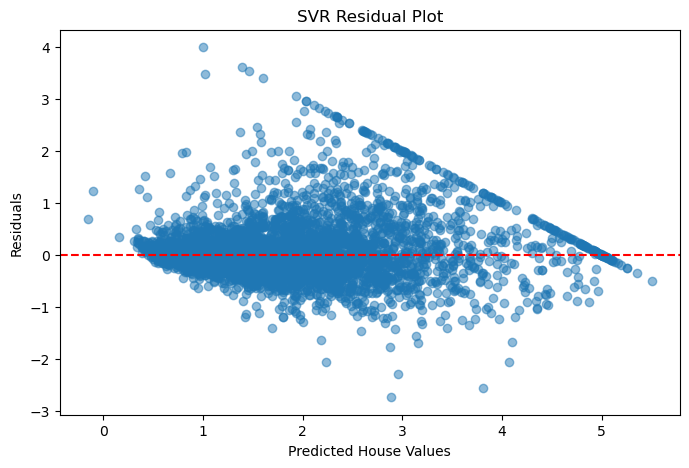

In [29]:
# Residual plot
plt.figure(figsize=(8, 5))

plt.scatter(y_test_pred, residuals, alpha=0.5)

plt.axhline(y=0, color='red', linestyle='--')

plt.title("SVR Residual Plot")
plt.xlabel("Predicted House Values")
plt.ylabel("Residuals")

plt.show()

In [30]:
# Actual vs predicted table
svr_results = pd.DataFrame({
    'Actual Values': y_test.values,
    'Predicted Values': y_test_pred,
    'Residuals': residuals.values
})

svr_results.head(10)

,Actual Values,Predicted Values,Residuals
0,0.47700,0.516472,-0.039472
1,0.45800,1.568429,-1.110429
2,5.00001,3.597803,1.402207
3,2.18600,2.491082,-0.305082
4,2.78000,2.568808,0.211192
5,1.58700,1.671660,-0.084660
6,1.98200,2.625384,-0.643384
7,1.57500,1.729185,-0.154185
8,3.40000,2.319095,1.080905
9,4.46600,4.730535,-0.264535


### SVR Conclusion

Support Vector Regression was implemented using an RBF kernel to predict median house values in the California Housing dataset.

The model achieved an MAE of 0.3986, RMSE of 0.5975, and R² score of 0.7276 on the test set.

The training R² was 0.7486, compared to the testing R² of 0.7276. The relatively small difference suggests consistent performance on training and unseen data.

Residual analysis and actual-versus-predicted visualizations were used to further examine prediction errors.

Overall, SVR demonstrated an ability to capture nonlinear relationships in the housing data, although prediction errors remain and further tuning could improve performance.

## Classification

In [31]:
# load dataset
# Create house-value categories
housing_df['house_category'] = pd.qcut(
    housing_df['target'],
    q=3,
    labels=['Low', 'Medium', 'High']
)

housing_df['house_category'].value_counts()

house_category
Low       6884
High      6880
Medium    6876
Name: count, dtype: int64

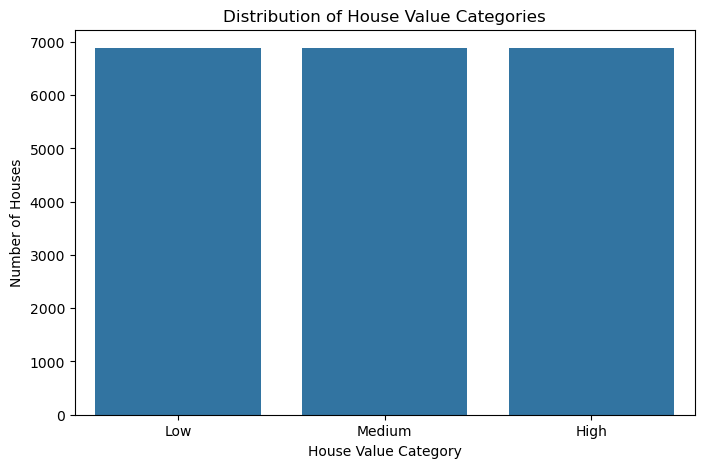

In [34]:
plt.figure(figsize=(8, 5))

sns.countplot(data=housing_df,x='house_category')

plt.title("Distribution of House Value Categories")
plt.xlabel("House Value Category")
plt.ylabel("Number of Houses")

plt.show()

In [35]:
# Separate features and classification target
X = housing_df.drop(columns=['target', 'house_category'])
y = housing_df['house_category']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (20640, 8)
Target shape: (20640,)


In [36]:
# split - train
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (16512, 8)
Testing features: (4128, 8)


In [38]:
# feature scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Training scaled shape:", X_train_scaled.shape)
print("Testing scaled shape:", X_test_scaled.shape)

Training scaled shape: (16512, 8)
Testing scaled shape: (4128, 8)


In [39]:
# Modelling
svc_model = SVC(kernel='rbf',C=1.0,probability=True,random_state=42)
svc_model.fit(X_train_scaled, y_train) #train model

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,True
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [40]:
# Training predictions
y_train_pred = svc_model.predict(X_train_scaled)

# Testing predictions
y_test_pred = svc_model.predict(X_test_scaled)

# Predicted class probabilities
y_test_proba = svc_model.predict_proba(X_test_scaled)

In [41]:
# Model evaluation
accuracy = accuracy_score(y_test, y_test_pred)

precision = precision_score(y_test, y_test_pred, average='weighted')

recall = recall_score(y_test, y_test_pred, average='weighted')

f1 = f1_score(y_test, y_test_pred, average='weighted')

roc_auc = roc_auc_score(y_test,y_test_proba,multi_class='ovr',average='weighted',labels=svc_model.classes_)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

Accuracy:  0.7517
Precision: 0.7595
Recall:    0.7517
F1 Score:  0.7544
ROC-AUC:   0.9042


In [42]:
# classification report
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

        High       0.84      0.77      0.80      1376
         Low       0.81      0.79      0.80      1377
      Medium       0.63      0.70      0.66      1375

    accuracy                           0.75      4128
   macro avg       0.76      0.75      0.75      4128
weighted avg       0.76      0.75      0.75      4128



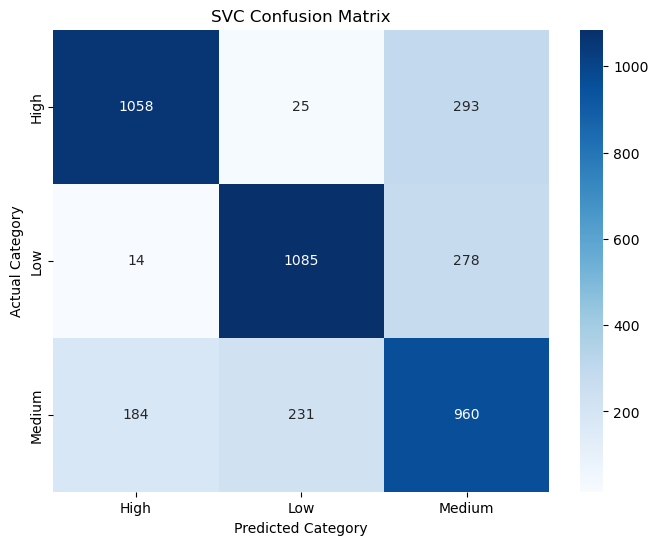

In [43]:
# confusion matrix
cm = confusion_matrix(y_test,y_test_pred,labels=svc_model.classes_)

plt.figure(figsize=(8, 6))

sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=svc_model.classes_,yticklabels=svc_model.classes_)

plt.title("SVC Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.show()

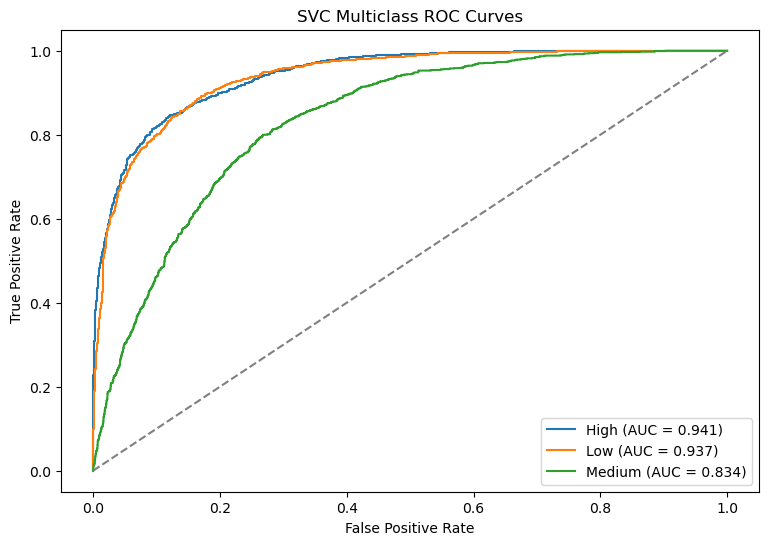

In [44]:
# multi-class ROC
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

classes = svc_model.classes_

y_test_binary = label_binarize(y_test,classes=classes)

plt.figure(figsize=(9, 6))

for i, category in enumerate(classes):

    fpr, tpr, thresholds = roc_curve(y_test_binary[:, i],y_test_proba[:, i])

    roc_auc_class = auc(fpr, tpr)

    plt.plot(fpr,tpr,label=f'{category} (AUC = {roc_auc_class:.3f})')

plt.plot([0, 1],[0, 1],linestyle='--',color='gray')

plt.title("SVC Multiclass ROC Curves")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()

plt.show()

In [45]:
# training vs testing accuracy
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print("Training Accuracy:", round(train_accuracy, 4))
print("Testing Accuracy:", round(test_accuracy, 4))

Training Accuracy: 0.7593
Testing Accuracy: 0.7517


In [46]:
# Actual vs predicted
svc_results = pd.DataFrame({
    'Actual Category': y_test.values,
    'Predicted Category': y_test_pred
})

svc_results.head(10)

,Actual Category,Predicted Category
0,Low,Low
1,Medium,Medium
2,Medium,Medium
3,Medium,Medium
4,Medium,Medium
5,High,High
6,Low,Low
7,Low,Low
8,Low,Low
9,Low,Low


#### SVC conclusion

Support Vector Classification was implemented using an RBF kernel to classify California Housing observations into Low, Medium, and High house-value categories.

The model achieved an accuracy of 75.17%, weighted precision of 75.95%, weighted recall of 75.17%, weighted F1-score of 75.44%, and weighted multiclass ROC-AUC of 0.9042.

The training accuracy was 75.93%, while testing accuracy was 75.17%. The small difference indicates relatively consistent performance on training and unseen data.

The model performed better when identifying Low and High house-value categories than Medium categories, which had the lowest F1-score.

Overall, SVC demonstrated its ability to classify nonlinear patterns in the housing data, although there is room for improvement.

**Limitation:** The classification categories were generated from the original continuous target using quantile-based categorization. They are experimental labels rather than official housing classifications.